# IFJC4002 | Practical Artificial Intelligence with Python
## Case 2: Used Car Resale Price Prediction (Regression)
**Faculty of Intelligent Computing, Universiti Malaysia Perlis (UniMAP)**  
**Course Coordinator:** Ir. Dr. Marni Azira Markom  
**Group 1**  

---
### 🎯 Project Overview & Rubric Alignment:
1. **Task 1: Problem Definition & Data Analysis (CO1):** Target (`resale_price_rm`), input features, missing value audit, and statistical distributions.
2. **Task 2: Design, Preprocessing & Model Evaluation (CO2):** Pipeline preprocessing, Baseline model, algorithm comparison (Linear, Ridge, Random Forest, Gradient Boosting) with 5-Fold Cross Validation, reporting MAE, RMSE, and R².
3. **Task 3: Implementation, Deployment & Model Export (CO3):** Export pipeline to `.joblib`, save all evaluation logs, test predictions, and report charts.

**💾 ระบบบันทึกผลอัตโนมัติ (Automated Results Saving):**
เมื่อรันเสร็จสิ้น ระบบจะบันทึกผลทุกอย่างลงโฟลเดอร์ใน Google Drive โดยอัตโนมัติ ได้แก่:
- 📊 **รูปกราฟคุณภาพสูง 6 รูป** (`outputs/*.png` สำหรับใส่เล่มรายงาน 8-12 หน้า)
- 📑 **ตารางเปรียบเทียบโมเดล** (`outputs/model_comparison.csv`)
- 🚗 **ผลทำนายรายคันของ Test Set** (`outputs/test_predictions_detailed.csv`)
- 📝 **เอกสารสรุปผลการเทรนอย่างละเอียด** (`outputs/training_summary_report.txt`)
- ⚙️ **ไฟล์โมเดล Pipeline** (`models/car_price_pipeline.joblib`)
- 📋 **ข้อมูล Metadata โมเดล** (`models/model_metadata.json`)
- 📂 **ชุดข้อมูลที่แบ่งแล้ว** (`data/processed/train_data.csv` และ `test_data.csv`)

### 1. Mount Google Drive & Environment Setup

In [1]:
import os
import sys

# Mount Drive if running on Google Colab
try:
    import google.colab
    IN_COLAB = True
    from google.colab import drive
    drive.mount('/content/drive')

    project_dir = '/content/drive/MyDrive/project_1_unimap'
    if os.path.exists(project_dir):
        os.chdir(project_dir)
        print(f"✅ Successfully changed directory to: {os.getcwd()}")
    else:
        print(f"⚠️ Project directory not found at {project_dir}. Working in: {os.getcwd()}")
except ImportError:
    IN_COLAB = False
    print("💻 Running in local Python environment.")

# Ensure output directories exist
os.makedirs('outputs', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('data/processed', exist_ok=True)
print("✅ Created directories: outputs/, models/, data/processed/")

Mounted at /content/drive
✅ Successfully changed directory to: /content/drive/MyDrive/project_1_unimap
✅ Created directories: outputs/, models/, data/processed/


### 2. Import Libraries

In [2]:
import datetime
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.dpi'] = 150
print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


### 3. Load Dataset

In [3]:
candidate_paths = [
    'data/raw/02_Used_Car_Price.xlsx',
    '/content/drive/MyDrive/project_1_unimap/data/raw/02_Used_Car_Price.xlsx',
    '../data/raw/02_Used_Car_Price.xlsx',
    '02_Used_Car_Price.xlsx'
]

data_path = None
for p in candidate_paths:
    if os.path.exists(p):
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError("❌ Could not find 02_Used_Car_Price.xlsx. Please ensure file exists in Drive.")

df = pd.read_excel(data_path)
print(f"✅ Dataset loaded from: {data_path}")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head())

✅ Dataset loaded from: data/raw/02_Used_Car_Price.xlsx
Shape: 2000 rows, 10 columns



,record_id,vehicle_age_years,mileage_km,engine_size_l,fuel_type,transmission,market_segment,condition_rating,previous_owners,resale_price_rm
0,P02_0001,10.0,128821.0,1.4,Diesel,Automatic,Mid_Range,4,3,45790.27
1,P02_0002,4.0,113932.0,2.7,Diesel,Automatic,Premium,5,1,182629.02
2,P02_0003,16.0,244900.0,2.0,Diesel,Automatic,Mid_Range,3,3,19605.97
3,P02_0004,15.0,344608.0,3.5,Petrol,Automatic,Premium,3,4,45693.78
4,P02_0005,3.0,33969.0,2.3,Petrol,Manual,Premium,3,0,197152.29


## 📊 Task 1: Exploratory Data Analysis & Automated Graph Saving (CO1)

In [4]:
# Missing value check & descriptive statistics
missing = df.isnull().sum()
print("=== Missing Values Audit ===")
print(missing[missing > 0])

num_cols = ['vehicle_age_years', 'mileage_km', 'engine_size_l', 'condition_rating', 'previous_owners', 'resale_price_rm']
stats_summary = df[num_cols].describe().round(2)
display(stats_summary)
stats_summary.to_csv('outputs/descriptive_statistics.csv')
print("💾 Saved: outputs/descriptive_statistics.csv")

=== Missing Values Audit ===
vehicle_age_years    16
mileage_km           16
dtype: int64


,vehicle_age_years,mileage_km,engine_size_l,condition_rating,previous_owners,resale_price_rm
count,1984.00,1984.00,2000.00,2000.00,2000.00,2000.00
mean,8.99,157660.92,2.25,3.64,1.92,66797.37
std,5.46,112655.74,0.72,0.94,1.21,57163.40
min,0.00,500.00,1.00,1.00,0.00,6005.89
25%,4.00,68526.25,1.60,3.00,1.00,26210.98
50%,9.00,133943.00,2.20,4.00,2.00,48592.31
75%,14.00,228767.50,2.90,4.00,3.00,87791.80
max,18.00,490559.00,3.50,5.00,4.00,398191.43


💾 Saved: outputs/descriptive_statistics.csv


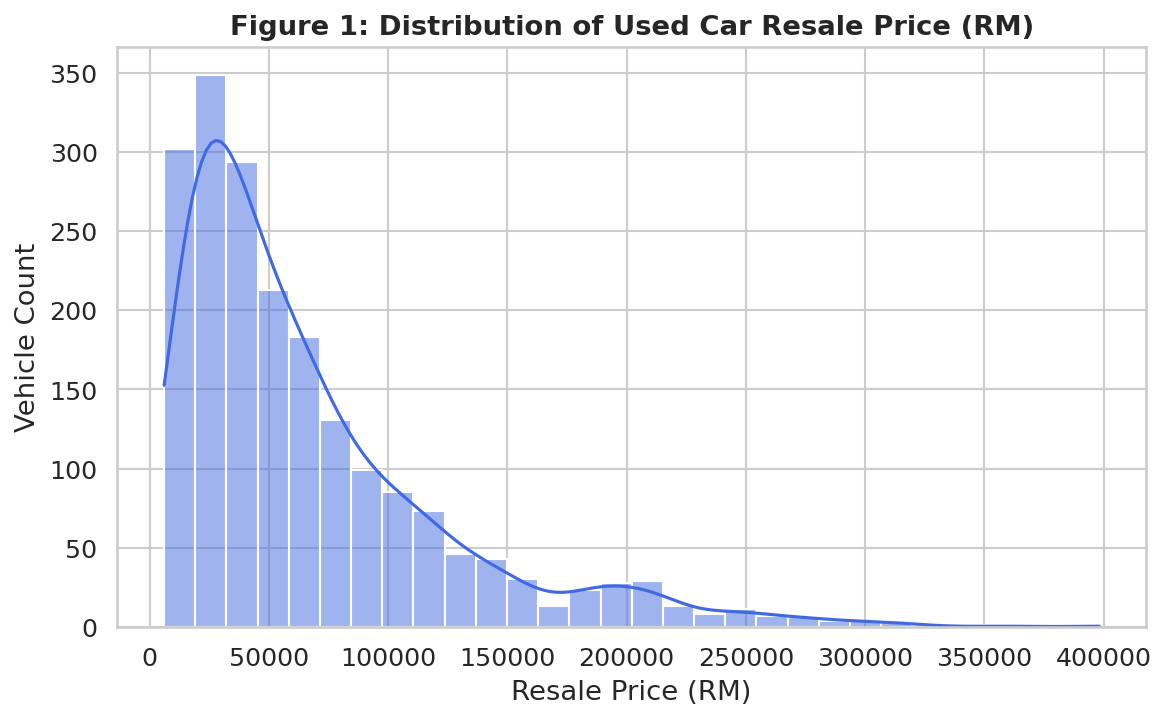

💾 Saved: outputs/01_price_distribution.png


/tmp/ipykernel_471/1315928699.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='market_segment', y='resale_price_rm', data=df, palette='Set2')


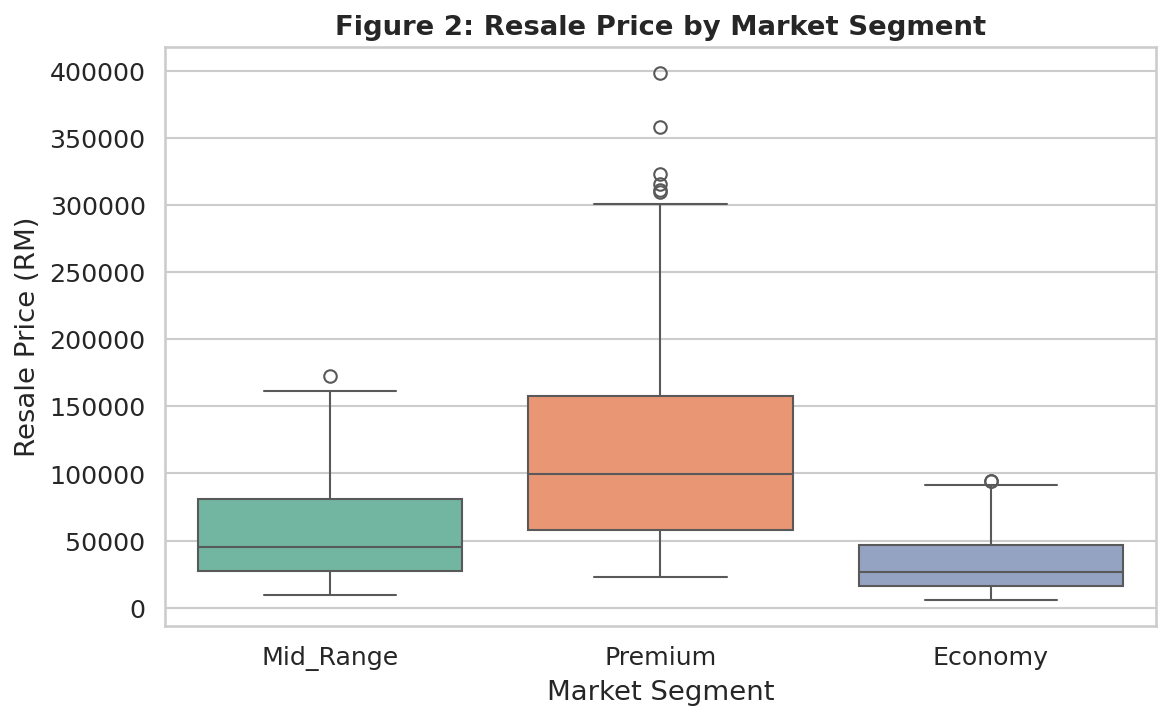

💾 Saved: outputs/02_market_segment_boxplot.png


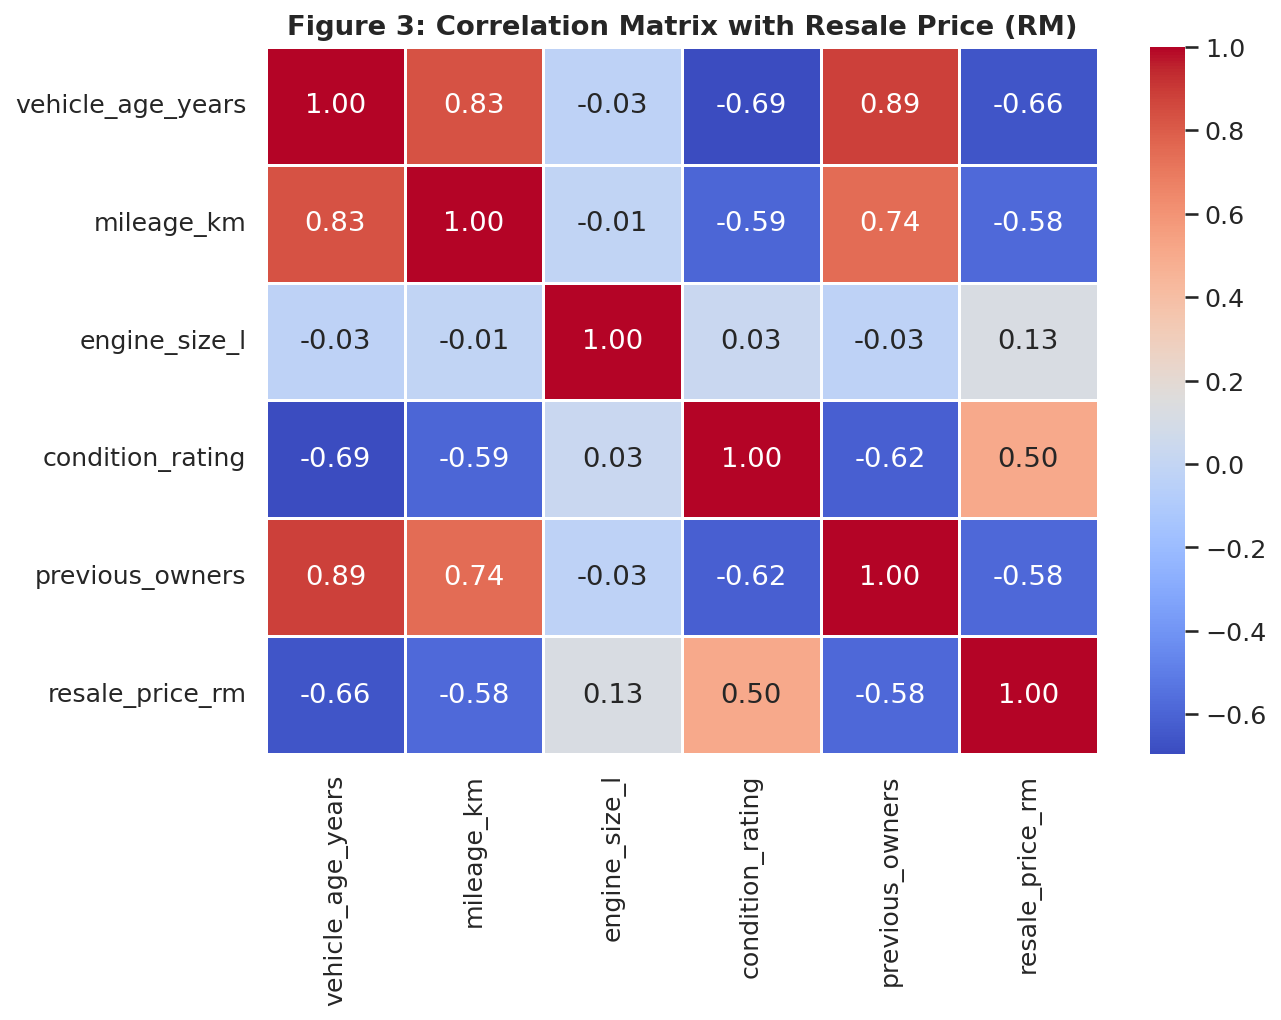

💾 Saved: outputs/03_correlation_heatmap.png


In [5]:
# Figure 1: Resale Price Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['resale_price_rm'], kde=True, color='royalblue', bins=30)
plt.title('Figure 1: Distribution of Used Car Resale Price (RM)', fontweight='bold')
plt.xlabel('Resale Price (RM)')
plt.ylabel('Vehicle Count')
plt.tight_layout()
plt.savefig('outputs/01_price_distribution.png', bbox_inches='tight')
plt.show()
print("💾 Saved: outputs/01_price_distribution.png")

# Figure 2: Resale Price by Market Segment Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x='market_segment', y='resale_price_rm', data=df, palette='Set2')
plt.title('Figure 2: Resale Price by Market Segment', fontweight='bold')
plt.xlabel('Market Segment')
plt.ylabel('Resale Price (RM)')
plt.tight_layout()
plt.savefig('outputs/02_market_segment_boxplot.png', bbox_inches='tight')
plt.show()
print("💾 Saved: outputs/02_market_segment_boxplot.png")

# Figure 3: Correlation Heatmap
plt.figure(figsize=(9, 7))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Figure 3: Correlation Matrix with Resale Price (RM)', fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/03_correlation_heatmap.png', bbox_inches='tight')
plt.show()
print("💾 Saved: outputs/03_correlation_heatmap.png")

## ⚙️ Task 2: Data Preprocessing, Model Training & Evaluation (CO2)

In [6]:
# Feature selection & Splitting (80% Train, 20% Test)
feature_cols = [
    'vehicle_age_years', 'mileage_km', 'engine_size_l',
    'fuel_type', 'transmission', 'market_segment',
    'condition_rating', 'previous_owners'
]
X = df[feature_cols]
y = df['resale_price_rm']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"✅ Split complete: Train = {len(X_train)} samples | Test = {len(X_test)} samples")

# Save split datasets to data/processed/
train_export = X_train.copy()
train_export['resale_price_rm'] = y_train
train_export.to_csv('data/processed/train_data.csv', index=False)

test_export = X_test.copy()
test_export['resale_price_rm'] = y_test
test_export.to_csv('data/processed/test_data.csv', index=False)
print("💾 Saved split datasets: data/processed/train_data.csv & test_data.csv")

# Preprocessing pipeline
numeric_features = ['vehicle_age_years', 'mileage_km', 'engine_size_l', 'condition_rating', 'previous_owners']
categorical_features = ['fuel_type', 'transmission', 'market_segment']

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, numeric_features),
    ('cat', cat_transformer, categorical_features)
])
print("✅ Preprocessing ColumnTransformer ready.")

✅ Split complete: Train = 1600 samples | Test = 400 samples
💾 Saved split datasets: data/processed/train_data.csv & test_data.csv
✅ Preprocessing ColumnTransformer ready.


In [7]:
# 1. Baseline Model
y_train_mean = y_train.mean()
y_base_pred = np.full_like(y_test, fill_value=y_train_mean)

mae_base = mean_absolute_error(y_test, y_base_pred)
rmse_base = root_mean_squared_error(y_test, y_base_pred)
r2_base = r2_score(y_test, y_base_pred)

results = [{
    'Model': 'Baseline (Mean Predictor)',
    '5-Fold CV R²': 0.0,
    'Test MAE (RM)': round(mae_base, 2),
    'Test RMSE (RM)': round(rmse_base, 2),
    'Test R²': round(r2_base, 4)
}]

# 2. Train & Compare Candidate Models
candidate_models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

trained_pipelines = {}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
predictions_dict = {'actual_resale_price_rm': y_test.values, 'baseline_pred': y_base_pred}

for name, model in candidate_models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2').mean()
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        '5-Fold CV R²': round(cv_r2, 4),
        'Test MAE (RM)': round(mae, 2),
        'Test RMSE (RM)': round(rmse, 2),
        'Test R²': round(r2, 4)
    })
    trained_pipelines[name] = pipe
    predictions_dict[f'{name}_pred'] = np.round(y_pred, 2)

# Model Comparison Table
comparison_df = pd.DataFrame(results)
print("\n" + "=" * 75)
print("MODEL COMPARISON RESULTS")
print("=" * 75)
display(comparison_df)
comparison_df.to_csv('outputs/model_comparison.csv', index=False)
print("💾 Saved: outputs/model_comparison.csv")

# Save detailed test predictions CSV
test_preds_df = pd.DataFrame(predictions_dict, index=X_test.index)
test_preds_df = pd.concat([X_test, test_preds_df], axis=1)
test_preds_df.to_csv('outputs/test_predictions_detailed.csv', index=False)
print("💾 Saved: outputs/test_predictions_detailed.csv")


MODEL COMPARISON RESULTS


,Model,5-Fold CV R²,Test MAE (RM),Test RMSE (RM),Test R²
0,Baseline (Mean Predictor),0.0000,41538.00,56184.62,-0.0000
1,Linear Regression,0.8106,17070.46,24317.06,0.8127
2,Ridge Regression,0.8106,17057.41,24324.55,0.8126
3,Random Forest Regressor,0.9650,5990.65,10215.71,0.9669
4,Gradient Boosting Regressor,0.9716,5649.50,9229.92,0.9730


💾 Saved: outputs/model_comparison.csv
💾 Saved: outputs/test_predictions_detailed.csv


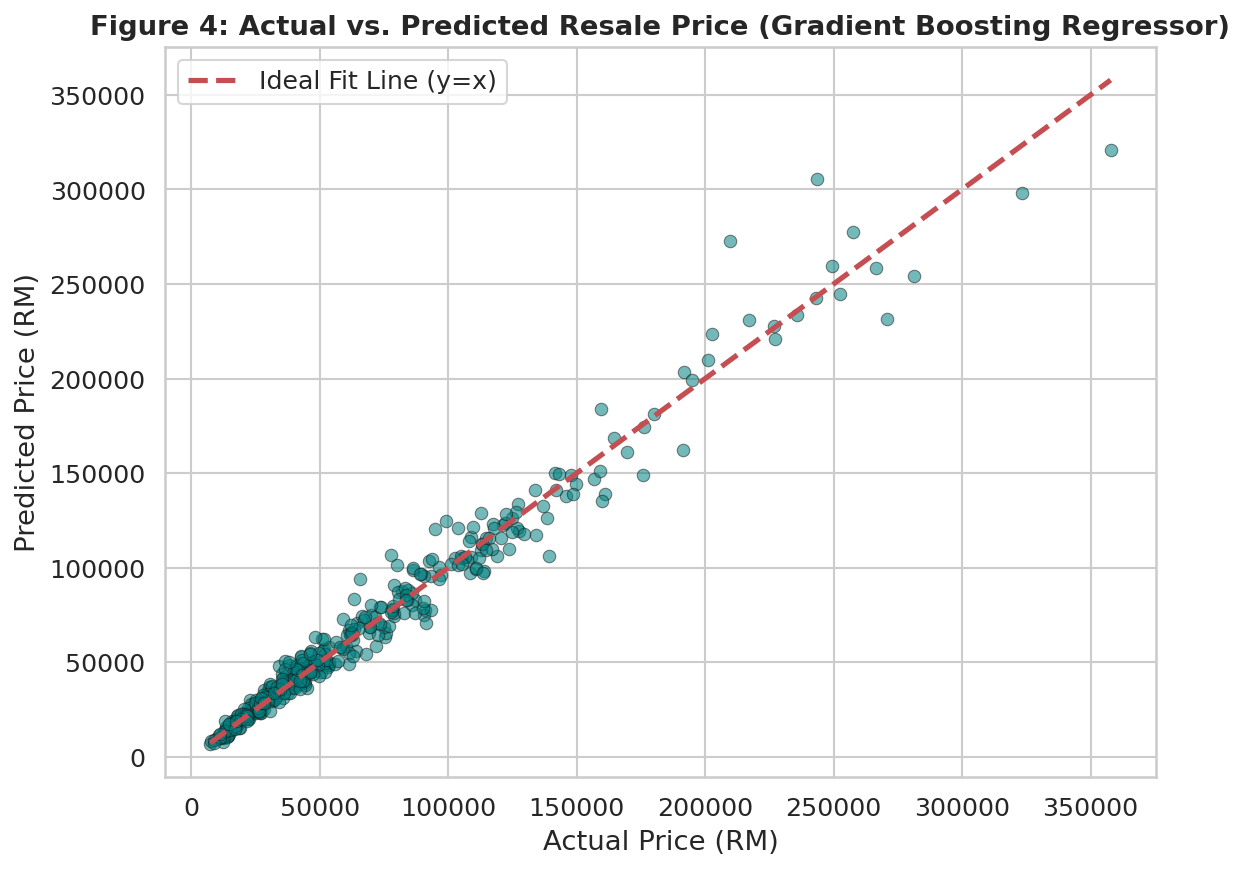

💾 Saved: outputs/04_actual_vs_predicted.png


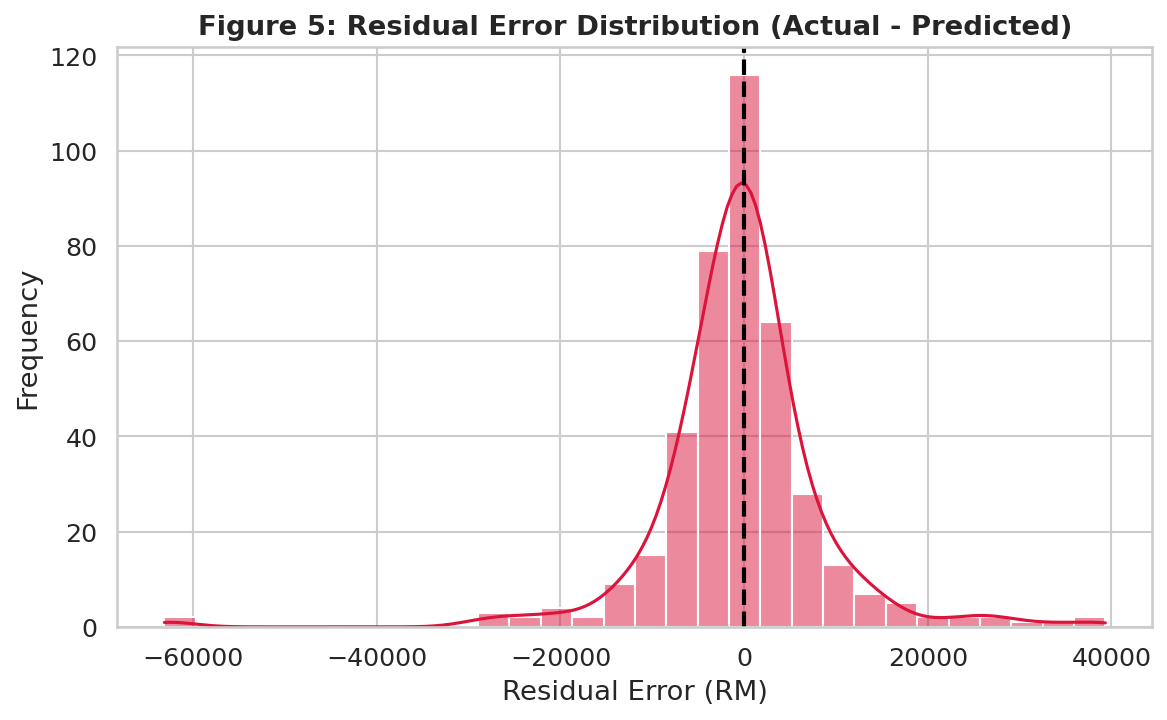

💾 Saved: outputs/05_residuals_distribution.png


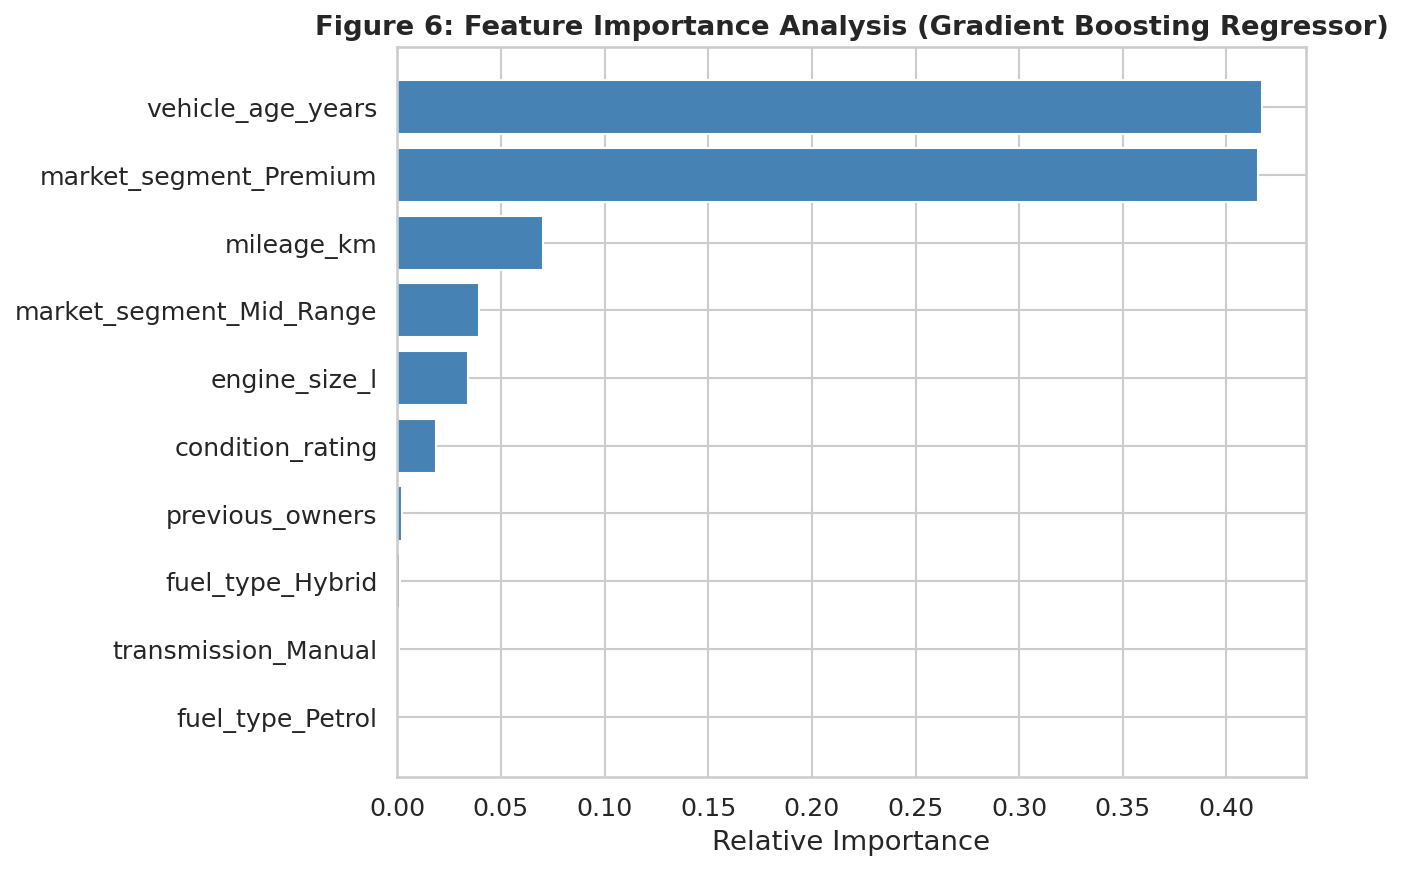

💾 Saved: outputs/06_feature_importance.png
💾 Saved: outputs/feature_importances.csv


In [8]:
# Figure 4: Actual vs Predicted Resale Price (Best Model)
best_model_name = comparison_df.sort_values(by='Test R²', ascending=False).iloc[0]['Model']
best_pipe = trained_pipelines[best_model_name]
y_best_pred = best_pipe.predict(X_test)
residuals = y_test - y_best_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_best_pred, alpha=0.55, color='teal', edgecolors='k', linewidth=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2.5, label='Ideal Fit Line (y=x)')
plt.title(f'Figure 4: Actual vs. Predicted Resale Price ({best_model_name})', fontweight='bold')
plt.xlabel('Actual Price (RM)')
plt.ylabel('Predicted Price (RM)')
plt.legend()
plt.tight_layout()
plt.savefig('outputs/04_actual_vs_predicted.png', bbox_inches='tight')
plt.show()
print("💾 Saved: outputs/04_actual_vs_predicted.png")

# Figure 5: Residuals Distribution
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='crimson', bins=30)
plt.axvline(0, color='black', linestyle='--', lw=2)
plt.title('Figure 5: Residual Error Distribution (Actual - Predicted)', fontweight='bold')
plt.xlabel('Residual Error (RM)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('outputs/05_residuals_distribution.png', bbox_inches='tight')
plt.show()
print("💾 Saved: outputs/05_residuals_distribution.png")

# Figure 6: Feature Importances (Tree-based model)
if hasattr(best_pipe.named_steps['regressor'], 'feature_importances_'):
    encoded_cat_names = best_pipe.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_features)
    all_feat_names = list(numeric_features) + list(encoded_cat_names)
    importances = best_pipe.named_steps['regressor'].feature_importances_
    feat_imp_df = pd.DataFrame({'Feature': all_feat_names, 'Importance': importances}).sort_values('Importance', ascending=True)

    plt.figure(figsize=(9, 6))
    plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'], color='steelblue')
    plt.title(f'Figure 6: Feature Importance Analysis ({best_model_name})', fontweight='bold')
    plt.xlabel('Relative Importance')
    plt.tight_layout()
    plt.savefig('outputs/06_feature_importance.png', bbox_inches='tight')
    plt.show()
    print("💾 Saved: outputs/06_feature_importance.png")
    feat_imp_df.sort_values('Importance', ascending=False).to_csv('outputs/feature_importances.csv', index=False)
    print("💾 Saved: outputs/feature_importances.csv")

## 💾 Task 3: Export Model, Summary Report & Verification (CO3)

In [9]:
# Export final model pipeline
model_export_path = 'models/car_price_pipeline.joblib'
joblib.dump(best_pipe, model_export_path)
print(f"✅ Successfully exported model to: {model_export_path}")

# Save Model Metadata JSON
metadata = {
    'project_title': 'Used Car Resale Price Prediction',
    'course': 'IFJC4002 Practical AI with Python (UniMAP)',
    'training_timestamp': datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'total_dataset_samples': len(df),
    'train_samples': len(X_train),
    'test_samples': len(X_test),
    'selected_model': best_model_name,
    'target_column': 'resale_price_rm',
    'features': feature_cols,
    'evaluation_summary': comparison_df.to_dict(orient='records')
}
with open('models/model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)
print("💾 Saved: models/model_metadata.json")

# Generate Comprehensive Text Report for Students
report_text = f"""========================================================================
IFJC4002 PRACTICAL ARTIFICIAL INTELLIGENCE - PROJECT EXECUTION SUMMARY
Case 2: Used Car Price Prediction (Regression)
Generated on: {datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
========================================================================

1. DATASET CHARACTERISTICS:
   - Total Samples: {len(df)} records
   - Target Variable: resale_price_rm (Mean: RM {df['resale_price_rm'].mean():,.2f}, Range: RM {df['resale_price_rm'].min():,.2f} - RM {df['resale_price_rm'].max():,.2f})
   - Missing Values Handled: vehicle_age_years ({df['vehicle_age_years'].isnull().sum()}), mileage_km ({df['mileage_km'].isnull().sum()})
   - Train Split: {len(X_train)} samples (80%)
   - Test Split: {len(X_test)} samples (20%)

2. MODEL EVALUATION & COMPARISON TABLE:
{comparison_df.to_string(index=False)}

3. SELECTED FINAL MODEL:
   - Best Model: {best_model_name}
   - Exported Pipeline: {model_export_path}

4. ARTIFACTS SAVED IN GOOGLE DRIVE:
   - outputs/01_price_distribution.png
   - outputs/02_market_segment_boxplot.png
   - outputs/03_correlation_heatmap.png
   - outputs/04_actual_vs_predicted.png
   - outputs/05_residuals_distribution.png
   - outputs/06_feature_importance.png
   - outputs/model_comparison.csv
   - outputs/test_predictions_detailed.csv
   - outputs/descriptive_statistics.csv
   - models/car_price_pipeline.joblib
   - models/model_metadata.json
   - data/processed/train_data.csv & test_data.csv
========================================================================
"""
with open('outputs/training_summary_report.txt', 'w') as f:
    f.write(report_text)
print("💾 Saved: outputs/training_summary_report.txt")

# Verification Inference Check
reloaded_pipe = joblib.load(model_export_path)
test_vector = pd.DataFrame([{
    'vehicle_age_years': 4.0,
    'mileage_km': 65000.0,
    'engine_size_l': 2.0,
    'fuel_type': 'Petrol',
    'transmission': 'Automatic',
    'market_segment': 'Mid_Range',
    'condition_rating': 4,
    'previous_owners': 1
}])
sample_price = reloaded_pipe.predict(test_vector)[0]
print(f"\n🎯 Test Inference on Sample: RM {sample_price:,.2f}")
print("\n🎉 ALL RESULTS AND ARTIFACTS HAVE BEEN SUCCESSFULLY SAVED TO DRIVE!")

✅ Successfully exported model to: models/car_price_pipeline.joblib
💾 Saved: models/model_metadata.json
💾 Saved: outputs/training_summary_report.txt

🎯 Test Inference on Sample: RM 79,936.00

🎉 ALL RESULTS AND ARTIFACTS HAVE BEEN SUCCESSFULLY SAVED TO DRIVE!
